# GSE252027 数据与差异分析基线

本笔记讲解主队列样本、表达矩阵及 D7 对 D0 的探索性结果。先运行阶段 01 工程脚本，再逐格阅读已生成的输出。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

# 从项目根或 notebooks 目录启动时都定位到项目根。
cwd = Path.cwd()
ROOT = next(p for p in (cwd, *cwd.parents) if (p / 'datasets/GSE252027').is_dir())
OUT = ROOT / 'outputs/01_preprocessing_differential'

## 样本分组

表 1 GSE252027 成纤维细胞各采样时间点的提交文库数。一个 GSM 对应一个文库。

In [2]:
samples = pd.read_csv(ROOT / 'datasets/GSE252027/metadata/samples_FB.csv').set_index('gsm')
groups = samples.groupby('day').size().rename('提交文库数').rename_axis('时间点（天）')
display(groups.to_frame())

,提交文库数
时间点（天）,
0,4
1,4
3,4
7,4
14,4
28,4


## 从样本编号追踪到 TPM

表 2 Cthrc1 在各时间点的文库数及平均 TPM。均值使用全部提交文库，D3 和 D28 的正式纳入仍待核查。

In [3]:
tpm = pd.read_csv(OUT / 'matrices/FB_TPM.tsv.gz', sep='\t', index_col=0)
assert tpm.columns.equals(samples.index)
gene_id = 'ENSMUSG00000054196'  # Cthrc1 的稳定基因编号。
gene = samples[['day']].assign(TPM=tpm.loc[gene_id])
display(gene.groupby('day')['TPM'].agg(提交文库数='size', 平均TPM='mean').rename_axis('时间点（天）').round(3))

,提交文库数,平均TPM
时间点（天）,,
0,4,0.556
1,4,13.661
3,4,73.532
7,4,98.724
14,4,36.802
28,4,5.117


## 差异结果怎样读

表 3 Cthrc1 的 D7 对 D0 模型估计。TPM 用于看相对表达，工程模型使用长度缩放计数和样本分组。`log2表达倍数变化` 指效应方向和大小，`校正后P值` 指多重检验校正后的统计证据。

In [4]:
result = pd.read_csv(OUT / 'tables/discovery_D7_vs_D0.tsv', sep='\t', index_col=0)
display(result.loc[[gene_id], ['基因符号', 'log2表达倍数变化', '校正后P值', '通过差异筛选']])
print('通过预设差异门槛的基因数', result['通过差异筛选'].eq('是').sum())

,基因符号,log2表达倍数变化,校正后P值,通过差异筛选
基因ID,,,,
ENSMUSG00000054196,Cthrc1,7.832189,2.677949e-139,是


通过预设差异门槛的基因数 1501


## 读时间分布图

每个点是一个文库，折线连接各时间组均值，横轴按实际采样日绘制。

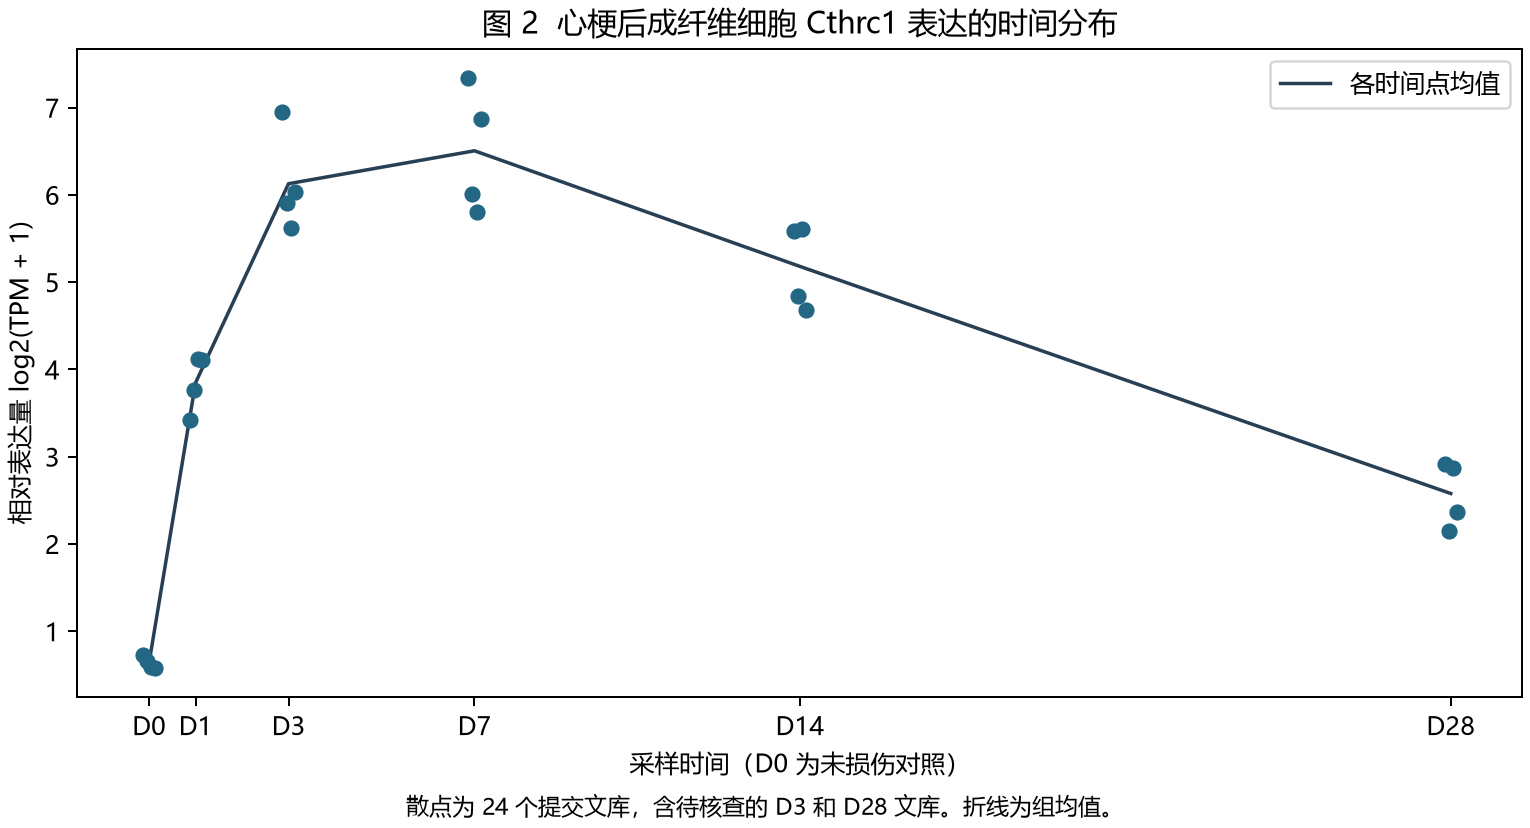

In [5]:
display(Image(filename=str(OUT / 'figures/02_cthrc1_time_profile.png'), width=850))

本轮代码的完整口径见 [阶段 01 方案](../experiments/01_preprocessing_differential/protocol.md)。全时段差异分析和之后三个阶段的状态见 [实验总览](../experiments/README.md)。